# Lab 5 (Part B): Titanic Survival Classification

**Course:** Introduction to Artificial Intelligence (AI-101L)   **Student:** Arham Rizwan

Goal: treat survival on the Titanic as a machine learning problem, from the raw CSV to a saved model.

Steps: (1) load and explore, (2) preprocess and engineer features, (3) split and scale, (4) train and compare Logistic Regression, Decision Tree and Random Forest, (5) tune with `GridSearchCV`, (6) save the winning model and the encoders. The in-lab exercises and the home assignment (a leak-free `Pipeline`) follow.

The rule used throughout: anything learned from data (medians, the scaler) is fitted on the **training** part only and merely applied to the test part.

In [1]:
import numpy as np, pandas as pd, pickle, joblib, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)

RS = 42
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
raw = pd.read_csv("data/titanic.csv")
print(raw.shape)
raw.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Load and explore

In [2]:
print("Missing values per column (only columns with gaps):")
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())
rate = raw["survived"].mean()
print(f"\nSurvival rate: {rate:.3f}")
print(f"Baseline (always predict 'did not survive'): {1 - rate:.3f}")
print("\nSurvival rate by sex:");    print(raw.groupby("sex")["survived"].mean().round(3).to_string())
print("\nSurvival rate by class:");  print(raw.groupby("pclass")["survived"].mean().round(3).to_string())
print("\nSurvival rate by port:");   print(raw.groupby("embarked")["survived"].mean().round(3).to_string())

Missing values per column (only columns with gaps):
age            177
embarked         2
deck           688
embark_town      2

Survival rate: 0.384
Baseline (always predict 'did not survive'): 0.616

Survival rate by sex:
sex
female    0.742
male      0.189

Survival rate by class:
pclass
1    0.630
2    0.473
3    0.242

Survival rate by port:
embarked
C    0.554
Q    0.390
S    0.337


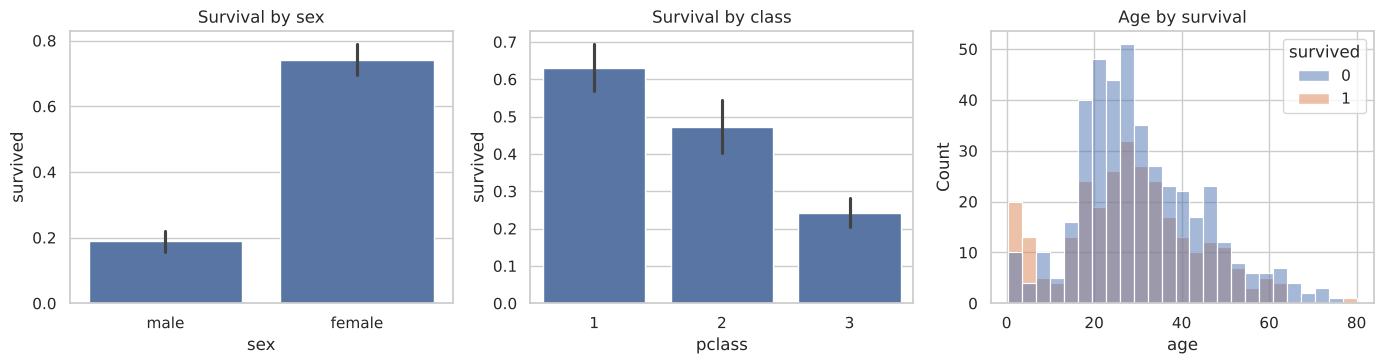

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.barplot(data=raw, x="sex", y="survived", ax=ax[0]); ax[0].set_title("Survival by sex")
sns.barplot(data=raw, x="pclass", y="survived", ax=ax[1]); ax[1].set_title("Survival by class")
sns.histplot(data=raw, x="age", hue="survived", bins=25, ax=ax[2]); ax[2].set_title("Age by survival")
plt.tight_layout(); plt.show()

## 2. Select and name the columns
Seven raw columns are used: class, sex, age, siblings/spouses, parents/children, fare and port. `deck` is dropped because 77% of it is missing, and `class`, `who`, `alive`, `adult_male`, `alone` and `embark_town` repeat information (or the answer) found elsewhere. `alive` is just the target written out, so it must never be used as a feature.

The categories are given readable names so that the saved encoders can be reused by the Lab 6 API.

In [4]:
print("Deck missing: %.1f%%" % (raw["deck"].isna().mean() * 100))
d = pd.DataFrame({
    "PClass":   raw["pclass"].map({1: "First", 2: "Second", 3: "Third"}),
    "Gender":   raw["sex"].str.capitalize(),
    "Age":      raw["age"],
    "SibSp":    raw["sibsp"],
    "Parch":    raw["parch"],
    "Fare":     raw["fare"],
    "Embarked": raw["embarked"].map({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"}),
})
y = raw["survived"]
d.head()

Deck missing: 77.2%


,PClass,Gender,Age,SibSp,Parch,Fare,Embarked
0,Third,Male,22.0,1,0,7.2500,Southampton
1,First,Female,38.0,1,0,71.2833,Cherbourg
2,Third,Female,26.0,0,0,7.9250,Southampton
3,First,Female,35.0,1,0,53.1000,Southampton
4,Third,Male,35.0,0,0,8.0500,Southampton


## 3. Split first, then preprocess
The stratified split is made on the raw table, before any median or scaler is computed. `prep()` learns the age/fare medians, the most common port and the scaler from the training rows only, then applies them to both parts. It also builds the engineered features `FamilySize = SibSp + Parch + 1` and `IsAlone`.

Encoders use fixed category lists, which does not depend on the data. Note that label encoding gives Embarked an arbitrary order (0, 1, 2); this is acceptable for trees but is a mild weakness for logistic regression.

In [5]:
d_train, d_test, y_train, y_test = train_test_split(d, y, test_size=0.2, stratify=y, random_state=RS)
print("train:", d_train.shape, " test:", d_test.shape)
print("survival rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

enc_pclass   = LabelEncoder().fit(["First", "Second", "Third"])
enc_gender   = LabelEncoder().fit(["Female", "Male"])
enc_embarked = LabelEncoder().fit(["Cherbourg", "Queenstown", "Southampton"])
NUM = ["Age", "SibSp", "Parch", "Fare"]

def prep(train, test, family=True):
    tr, te = train.copy(), test.copy()
    fill = {"Age": tr["Age"].median(), "Fare": tr["Fare"].median(), "Embarked": tr["Embarked"].mode()[0]}
    for part in (tr, te):
        part.fillna(fill, inplace=True)
        part["FamilySize"] = part["SibSp"] + part["Parch"] + 1
        part["IsAlone"] = (part["FamilySize"] == 1).astype(int)
        part["PClass"] = enc_pclass.transform(part["PClass"])
        part["Gender"] = enc_gender.transform(part["Gender"])
        part["Embarked"] = enc_embarked.transform(part["Embarked"])
    num = NUM + (["FamilySize"] if family else [])
    scaler = StandardScaler().fit(tr[num])
    tr[num] = scaler.transform(tr[num]); te[num] = scaler.transform(te[num])
    cols = ["PClass", "Gender", "Embarked"] + num + (["IsAlone"] if family else [])
    return tr[cols], te[cols], {"fill": fill, "scaler": scaler, "columns": cols}

Xtr, Xte, info = prep(d_train, d_test, family=True)
print("\nFilled with (training values only):", {k: (round(v, 2) if not isinstance(v, str) else v) for k, v in info["fill"].items()})
print("Missing after preprocessing:", int(Xtr.isna().sum().sum() + Xte.isna().sum().sum()))
Xtr.head()

train: (712, 7)  test: (179, 7)
survival rate  train: 0.383  test: 0.385

Filled with (training values only): {'Age': np.float64(28.5), 'Fare': np.float64(14.45), 'Embarked': 'Southampton'}
Missing after preprocessing: 0


,PClass,Gender,Embarked,Age,SibSp,Parch,Fare,FamilySize,IsAlone
692,2,1,2,-0.081135,-0.465084,-0.466183,0.513812,-0.556339,1
481,1,1,2,-0.081135,-0.465084,-0.466183,-0.662563,-0.556339,1
527,0,1,2,-0.081135,-0.465084,-0.466183,3.955399,-0.556339,1
855,2,0,2,-0.887827,-0.465084,0.727782,-0.467874,0.073412,0
801,1,0,2,0.110934,0.478335,0.727782,-0.115977,0.703162,0


## 4. Train and compare three models (default settings)

In [6]:
def evaluate(models, Xa, ya, Xb, yb):
    rows = {}
    for name, m in models.items():
        m.fit(Xa, ya)
        p = m.predict(Xb)
        score = m.predict_proba(Xb)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xb)
        rows[name] = {"train_acc": accuracy_score(ya, m.predict(Xa)), "test_acc": accuracy_score(yb, p),
                      "precision": precision_score(yb, p), "recall": recall_score(yb, p),
                      "f1": f1_score(yb, p), "auc": roc_auc_score(yb, score)}
    return pd.DataFrame(rows).T.round(3)

def three_models():
    return {"Logistic Regression": LogisticRegression(max_iter=1000, random_state=RS),
            "Decision Tree": DecisionTreeClassifier(random_state=RS),
            "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RS)}

baseline = 1 - y_test.mean()
print(f"Baseline accuracy on the test set: {baseline:.3f}  ({len(y_test)} test passengers, 1 passenger = {1/len(y_test):.3f})")
res = evaluate(three_models(), Xtr, y_train, Xte, y_test)
res

Baseline accuracy on the test set: 0.615  (179 test passengers, 1 passenger = 0.006)


,train_acc,test_acc,precision,recall,f1,auc
Logistic Regression,0.805,0.804,0.783,0.681,0.729,0.859
Decision Tree,0.983,0.782,0.727,0.696,0.711,0.758
Random Forest,0.983,0.799,0.754,0.710,0.731,0.830


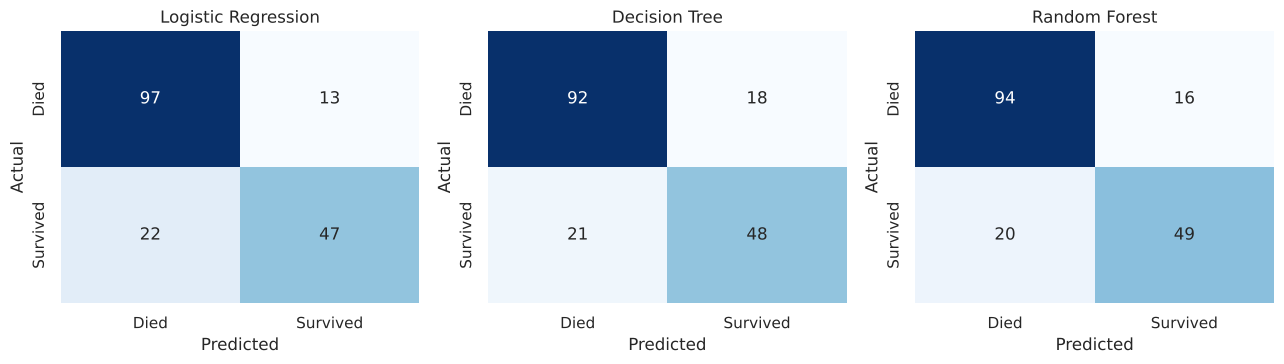

              precision    recall  f1-score   support

        Died       0.82      0.88      0.85       110
    Survived       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Logistic regression coefficients (features are scaled):
Gender       -2.527
PClass       -0.999
IsAlone      -0.571
Age          -0.475
SibSp        -0.273
FamilySize   -0.216
Embarked     -0.205
Parch        -0.064
Fare          0.089

Random forest importances:
Gender        0.272
Fare          0.257
Age           0.243
PClass        0.086
FamilySize    0.045
Embarked      0.034
SibSp         0.028
Parch         0.024
IsAlone       0.012


In [7]:
models = three_models()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, m) in zip(axes, models.items()):
    m.fit(Xtr, y_train)
    cm = confusion_matrix(y_test, m.predict(Xte))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
print(classification_report(y_test, models["Logistic Regression"].predict(Xte), target_names=["Died", "Survived"]))
lr = models["Logistic Regression"]
print("Logistic regression coefficients (features are scaled):")
print(pd.Series(lr.coef_[0], index=Xtr.columns).sort_values().round(3).to_string())
imp = pd.Series(models["Random Forest"].feature_importances_, index=Xtr.columns).sort_values(ascending=False)
print("\nRandom forest importances:"); print(imp.round(3).to_string())

## 5. Tune with GridSearchCV
Each model family gets a small grid. Selection uses 5-fold stratified, shuffled cross-validation on the **training** data only; the test set is not touched until the tuned models are scored once at the end.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RS), {"C": [0.01, 0.1, 1, 10, 100]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RS), {"max_depth": [3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=RS), {"n_estimators": [100, 300], "max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 3, 5]}),
}
tuned, rows = {}, []
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=cv, scoring="accuracy", n_jobs=1).fit(Xtr, y_train)
    tuned[name] = gs
    rows.append({"model": name, "best_cv_accuracy": gs.best_score_, "test_accuracy": gs.score(Xte, y_test), "best_params": gs.best_params_})
tuning = pd.DataFrame(rows).set_index("model")
tuning["best_cv_accuracy"] = tuning["best_cv_accuracy"].round(4); tuning["test_accuracy"] = tuning["test_accuracy"].round(4)
pd.set_option("display.max_colwidth", 100)
tuning

,best_cv_accuracy,test_accuracy,best_params
model,,,
Logistic Regression,0.8034,0.8045,{'C': 0.1}
Decision Tree,0.8160,0.7765,"{'max_depth': 4, 'min_samples_leaf': 10}"
Random Forest,0.8231,0.8101,"{'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 300}"


In [9]:
winner_name = tuning["best_cv_accuracy"].idxmax()
winner = tuned[winner_name].best_estimator_
print("Winner by cross-validation:", winner_name)
print(winner)
print("Test accuracy of the winner: %.4f (baseline %.3f)" % (accuracy_score(y_test, winner.predict(Xte)), baseline))

Winner by cross-validation: Random Forest
RandomForestClassifier(min_samples_leaf=3, n_estimators=300, random_state=42)
Test accuracy of the winner: 0.8101 (baseline 0.615)


## 6. Save the model and the encoders
The saved files are what Lab 6 loads. The scaler and the fill values are saved too, because new passengers must be preprocessed in exactly the same way.

In [10]:
joblib.dump(winner, "titanic_best_model.joblib")
for name, obj in {"pclass_encoder": enc_pclass, "gender_encoder": enc_gender, "embarked_encoder": enc_embarked}.items():
    with open(f"{name}.pkl", "wb") as f: pickle.dump(obj, f)
with open("preprocessing_info.pkl", "wb") as f: pickle.dump(info, f)

# reload and check that the saved model reproduces the test predictions
reloaded = joblib.load("titanic_best_model.joblib")
print("Reloaded model gives identical test predictions:", bool((reloaded.predict(Xte) == winner.predict(Xte)).all()))
print([f for f in sorted(os.listdir(".")) if f.endswith((".pkl", ".joblib")) and not f.startswith("diabetes")])

Reloaded model gives identical test predictions: True
['embarked_encoder.pkl', 'gender_encoder.pkl', 'pclass_encoder.pkl', 'preprocessing_info.pkl', 'titanic_best_model.joblib']


---
# In-Lab Exercises

## Exercise 1: with and without `FamilySize` and `IsAlone`
The three default models are trained twice, once with the two engineered features and once without. The scaler is refitted for each version.

In [11]:
Xtr_nf, Xte_nf, _ = prep(d_train, d_test, family=False)
with_f = evaluate(three_models(), Xtr, y_train, Xte, y_test)["test_acc"]
without_f = evaluate(three_models(), Xtr_nf, y_train, Xte_nf, y_test)["test_acc"]
ex1 = pd.DataFrame({"with FamilySize/IsAlone": with_f, "without": without_f})
ex1["delta (with - without)"] = (ex1.iloc[:, 0] - ex1.iloc[:, 1]).round(3)
print(f"One test passenger is worth {1/len(y_test):.3f} accuracy, so deltas of a few passengers are within noise.")
ex1

One test passenger is worth 0.006 accuracy, so deltas of a few passengers are within noise.


,with FamilySize/IsAlone,without,delta (with - without)
Logistic Regression,0.804,0.804,0.000
Decision Tree,0.782,0.816,-0.034
Random Forest,0.799,0.804,-0.005


## Exercise 2: ROC curve and AUC of the best model
The best model is the tuned winner from section 5.

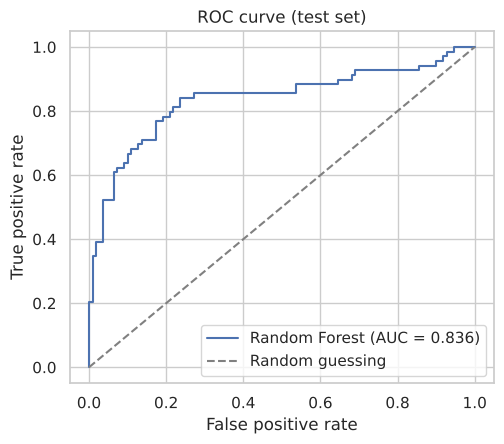

AUC of Random Forest: 0.836


In [12]:
proba = winner.predict_proba(Xte)[:, 1]
auc = roc_auc_score(y_test, proba)
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(5.2, 4.6))
plt.plot(fpr, tpr, label=f"{winner_name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random guessing")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve (test set)")
plt.legend(); plt.tight_layout(); plt.savefig("figures/roc_curve.png", dpi=150); plt.show()
print(f"AUC of {winner_name}: {auc:.3f}")

## Exercise 3: five-fold cross-validation
Stability of each model (default settings) on the preprocessed training data, with shuffled stratified folds.

In [13]:
rows = {}
for name, m in three_models().items():
    s = cross_val_score(m, Xtr, y_train, cv=cv, scoring="accuracy")
    rows[name] = {"mean": s.mean(), "std": s.std(), "min": s.min(), "max": s.max()}
pd.DataFrame(rows).T.round(3)

,mean,std,min,max
Logistic Regression,0.799,0.015,0.782,0.817
Decision Tree,0.789,0.010,0.776,0.803
Random Forest,0.803,0.021,0.775,0.831


## Exercise 4: add KNN and SVC
The same evaluation function is run, unchanged, on a dictionary that now has five models. Both new models are distance-based, which is the reason the numeric features were scaled.

In [14]:
five = three_models()
five["KNN"] = KNeighborsClassifier()
five["SVC"] = SVC(random_state=RS)
ex4 = evaluate(five, Xtr, y_train, Xte, y_test)
ex4.sort_values("test_acc", ascending=False)

,train_acc,test_acc,precision,recall,f1,auc
SVC,0.831,0.827,0.806,0.725,0.763,0.834
Logistic Regression,0.805,0.804,0.783,0.681,0.729,0.859
KNN,0.843,0.804,0.766,0.710,0.737,0.822
Random Forest,0.983,0.799,0.754,0.710,0.731,0.830
Decision Tree,0.983,0.782,0.727,0.696,0.711,0.758


## Exercise 5: Summary report
**Results (same stratified split, 179 test passengers, baseline 61.5%).** With default settings the five models score: SVC 82.7%, Logistic Regression 80.4%, KNN 80.4%, Random Forest 79.9%, Decision Tree 78.2%. After `GridSearchCV` the tuned Random Forest has the best cross-validated accuracy (82.3%) and scores 81.0% on the test set, ahead of the tuned Logistic Regression (80.3% CV, 80.5% test) and the tuned Decision Tree (81.6% CV, 77.7% test). Five-fold cross-validation of the default models gives 79.9% (LR), 78.9% (DT) and 80.3% (RF), with standard deviations of 1 to 2 points.

**How much do these differences mean?** One test passenger is worth 0.56 points, and the whole spread between the models is only 4 to 5 points (about 8 passengers). The models are not clearly separable on this data. Every model beats the baseline by roughly 16 to 21 points, so they have learned real structure: sex, class, age and fare carry the signal (women survived at 74% against 19% for men, and first class at 63% against 24% for third).

**Engineered features.** Adding `FamilySize` and `IsAlone` did not help: the accuracy change was 0.0 points for logistic regression, -0.5 for the random forest and -3.4 for the decision tree. The random forest ranks both features low in importance.

**Which model to deploy.** I would deploy the tuned Random Forest, because it won the cross-validated comparison, which was done without looking at the test set, and it outputs survival probabilities that the API can return. Its ROC AUC is 0.836. The honest caveats are that logistic regression is within about 2 points in accuracy, has the highest AUC of the default models (0.859), and is simpler and easier to explain. If interpretability mattered more than the last point of accuracy, it would be the better choice. SVC had the best single test score, but it was not tuned or cross-validated, and one lucky split is not enough to pick it.

---
# Home Assignment: one `Pipeline` with a `ColumnTransformer`
Imputation, scaling and encoding all live inside the pipeline, so during cross-validation they are fitted again on each training fold only. The categorical columns use one-hot encoding here (no artificial order). The grid search covers the same three model families.

In [15]:
def add_family(frame):
    f = frame.copy()
    f["FamilySize"] = f["SibSp"] + f["Parch"] + 1
    f["IsAlone"] = (f["FamilySize"] == 1).astype(int)
    return f

P_train, P_test = add_family(d_train), add_family(d_test)
num_cols = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
cat_cols = ["PClass", "Gender", "Embarked"]
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ("bin", "passthrough", ["IsAlone"]),
])
pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000, random_state=RS))])
pipe_grid = [
    {"clf": [LogisticRegression(max_iter=1000, random_state=RS)], "clf__C": [0.01, 0.1, 1, 10, 100]},
    {"clf": [DecisionTreeClassifier(random_state=RS)], "clf__max_depth": [3, 4, 5, 6, 8, None], "clf__min_samples_leaf": [1, 5, 10]},
    {"clf": [RandomForestClassifier(random_state=RS)], "clf__n_estimators": [100, 300], "clf__max_depth": [4, 6, 8, None], "clf__min_samples_leaf": [1, 3, 5]},
]
pgs = GridSearchCV(pipe, pipe_grid, cv=cv, scoring="accuracy", n_jobs=1).fit(P_train, y_train)
p_best = pgs.best_estimator_
print("Best pipeline model:", type(p_best.named_steps["clf"]).__name__, {k: v for k, v in pgs.best_params_.items() if k != "clf"})
print("Pipeline CV accuracy : %.4f" % pgs.best_score_)
print("Pipeline test accuracy: %.4f" % accuracy_score(y_test, p_best.predict(P_test)))

Best pipeline model: RandomForestClassifier {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 300}
Pipeline CV accuracy : 0.8216
Pipeline test accuracy: 0.7989


In [16]:
manual_cv = tuning["best_cv_accuracy"].max()
diff = pgs.best_score_ - manual_cv
print(f"Manual approach best CV accuracy  : {manual_cv:.4f}  (medians and scaler fitted on the whole training set before CV)")
print(f"Pipeline approach best CV accuracy: {pgs.best_score_:.4f}  (everything refitted inside each fold)")
print(f"Difference (pipeline - manual)    : {diff:+.4f}  = {diff * len(y_train):+.1f} passengers out of {len(y_train)}")
print("\nPer-model comparison of best CV accuracy:")
per = pd.DataFrame({"manual": tuning["best_cv_accuracy"]})
res_p = pd.DataFrame(pgs.cv_results_)
res_p["model"] = res_p["param_clf"].map(lambda m: {"LogisticRegression": "Logistic Regression", "DecisionTreeClassifier": "Decision Tree", "RandomForestClassifier": "Random Forest"}[type(m).__name__])
per["pipeline"] = res_p.groupby("model")["mean_test_score"].max().round(4)
per["difference"] = (per["pipeline"] - per["manual"]).round(4)
per

Manual approach best CV accuracy  : 0.8231  (medians and scaler fitted on the whole training set before CV)
Pipeline approach best CV accuracy: 0.8216  (everything refitted inside each fold)
Difference (pipeline - manual)    : -0.0015  = -1.0 passengers out of 712

Per-model comparison of best CV accuracy:


,manual,pipeline,difference
model,,,
Logistic Regression,0.8034,0.8006,-0.0028
Decision Tree,0.8160,0.8132,-0.0028
Random Forest,0.8231,0.8216,-0.0015


### Home assignment: findings
- The pipeline picked the same model and the same hyper-parameters as the manual approach (Random Forest, `min_samples_leaf=3`, 300 trees, no depth limit). Its best cross-validated accuracy is 82.16%, against 82.31% for the manual approach. The difference is -0.15 points, which is one passenger out of 712.
- **Leakage.** In the manual approach the medians and the scaler were fitted on the whole training set before cross-validation, so each validation fold had helped to set the preprocessing used on it. The pipeline refits them inside every fold, which removes that leak, and the pipeline score is slightly lower, as the leakage argument predicts.
- The difference is tiny because the leaked information is only a median and a mean/standard deviation, which are stable statistics estimated from over 500 rows per fold. Leakage of this kind could matter far more with a small dataset or with target-dependent steps such as target encoding or feature selection.
- The two approaches also differ in more than leakage: the pipeline uses one-hot encoding instead of label codes. Since the gap is a single passenger, I cannot attribute it to either cause, and the test accuracies (80.1% manual, 79.9% pipeline) are equally close. The practical conclusion is that the pipeline is the safer design to keep, and in this case it does not change the result.
